# PART A: Conceptual Foundation

### 1. What is Regularization in Machine Learning? Why is it needed?

Regularization is a technique used to reduce overfitting by adding a penalty to large model coefficients.
It helps the model become simpler and generalize better to unseen data.

### 2. Difference between Ridge Regression (L2) and Lasso Regression (L1)

Ridge uses L2 regularization and reduces the size of coefficients without usually making them zero.
Lasso uses L1 regularization and can make some coefficients exactly zero, so it can also perform feature selection.

### 3. What is Cross-Validation and why is it important?

Cross-validation divides the training data into multiple parts and trains and validates the model several times.
It helps estimate how well the model will perform on unseen data and helps in selecting a reliable model.

### 4. Cross-Validation Techniques

**K-Fold Cross-Validation:**
The data is divided into K parts. The model is trained on K-1 parts and tested on the remaining part, repeating this until every part is used for validation.

**Stratified K-Fold Cross-Validation:**
It keeps the distribution of the target values similar in each fold. For regression, target values can first be divided into bins.

**Leave-One-Out Cross-Validation (LOOCV):**
The model is trained using all observations except one, and the remaining observation is used for validation. This is repeated for every observation.

**Time Series Split:**
The data is divided according to time, where earlier observations are used for training and later observations are used for validation. It prevents future data from being used to predict the past.

### 5. Why are tree-based models less sensitive to feature scaling?

Tree-based models make decisions using conditions such as whether a feature is greater or smaller than a particular value.
Therefore, changing the scale of a feature does not significantly affect the splitting process, so scaling is generally not required.


In [54]:
# Importing Libraries

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV
import numpy as np
from sklearn.model_selection import KFold, StratifiedKFold, LeaveOneOut, TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
import matplotlib.pyplot as plt

# PART B: Dataset Understanding & Preparation

In [55]:
data = pd.read_csv("Advanced_Regression_HousePrice_Dataset_3800.csv")

print("Dataset shape:", data.shape)
data.head()

Dataset shape: (3800, 12)


,property_id,sale_date,area_sqft,bedrooms,bathrooms,location_score,property_age,distance_city_km,near_school,near_metro,crime_rate_index,house_price_inr
0,200001,2014-01-01,2181,6,4,8.10,21,3.80,0,0,4.84,35154898
1,200002,2019-12-01,2383,5,4,5.30,28,10.90,1,1,2.89,26710893
2,200003,2016-10-01,1047,3,3,5.90,7,27.50,0,1,4.04,11216242
3,200004,2013-03-01,1753,4,3,7.00,27,12.10,0,0,3.28,21984310
4,200005,2013-07-01,1728,4,4,10.00,32,1.40,0,1,3.84,25080429


In [56]:
print("\nMissing values:")
print(data.isnull().sum())


Missing values:
property_id         0
sale_date           0
area_sqft           0
bedrooms            0
bathrooms           0
location_score      0
property_age        0
distance_city_km    0
near_school         0
near_metro          0
crime_rate_index    0
house_price_inr     0
dtype: int64


## Task 6: Identify Features and Target Variable

In [57]:
# Convert sale_date into numerical features
data["sale_date"] = pd.to_datetime(data["sale_date"])
data["sale_year"] = data["sale_date"].dt.year
data["sale_month"] = data["sale_date"].dt.month

# Target variable
y = data["house_price_inr"]

# Features
X = data.drop(columns=["house_price_inr", "property_id", "sale_date"])

print("Feature columns:")
print(X.columns.tolist())

print("\nTarget variable:")
print(y.name)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Feature columns:
['area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'property_age', 'distance_city_km', 'near_school', 'near_metro', 'crime_rate_index', 'sale_year', 'sale_month']

Target variable:
house_price_inr

Feature shape: (3800, 11)
Target shape: (3800,)


## Task 7: Train-Test Split

In [58]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

## Task 8: Basic Preprocessing

Continuous numerical features are standardized using StandardScaler.

In [59]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaled Training Data:")
print(X_train_scaled[:5])

print("\nScaled Testing Data:")
print(X_test_scaled[:5])

Scaled Training Data:
[[ 1.28512054  1.88879002  2.70553664 -0.35028874  0.44204424 -0.28951867
  -1.10114404  1.05548439  1.51203809  1.13174585  1.3121834 ]
 [-1.37634755 -1.79523517 -1.68760052  1.08640551  0.27991424 -0.96104093
   0.9081464   1.05548439  0.10393003 -0.85641213  1.60151666]
 [-0.03619995  0.41517994 -0.80897309  0.62666335 -0.93606074 -1.84622937
  -1.10114404 -0.9474323   0.20137695 -0.11085289  1.60151666]
 [ 0.11955156 -1.05843013 -0.80897309  1.31627659 -0.93606074 -1.3273258
   0.9081464  -0.9474323   0.15752584  0.8832261   0.7335169 ]
 [-0.99295922 -1.05843013  0.06965435  0.74159889 -1.01712574  0.88564529
  -1.10114404  1.05548439  0.92735654 -0.35937263  0.1548504 ]]

Scaled Testing Data:
[[-0.64893666 -1.05843013 -0.80897309 -1.32724083 -0.85499574  0.24464677
   0.9081464   1.05548439  2.42803917 -1.10493187  0.7335169 ]
 [ 1.03865662  1.88879002  2.70553664 -1.32724083 -1.17925574  0.97721651
  -1.10114404  1.05548439 -0.49536855  1.38026559 -0.1344828

# PART C: Regularized Linear Models

## Task 9: Implement Ridge Regression (L2)

In [60]:
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)

ridge_train_pred = ridge.predict(X_train_scaled)
ridge_train_mse = mean_squared_error(y_train, ridge_train_pred)

print("Ridge alpha:", ridge.alpha)
print("Ridge training MSE:", ridge_train_mse)


Ridge alpha: 1.0
Ridge training MSE: 6162302702017.45


## Task 10: Implement Lasso Regression (L1)

In [61]:
lasso = Lasso(alpha=1.0, max_iter=10000)
lasso.fit(X_train_scaled, y_train)

lasso_train_pred = lasso.predict(X_train_scaled)
lasso_train_mse = mean_squared_error(y_train, lasso_train_pred)

print("Lasso alpha:", lasso.alpha)
print("Lasso training MSE:", lasso_train_mse)


Lasso alpha: 1.0
Lasso training MSE: 6162283850266.747


## Task 11: Tune α using 5-Fold Cross-Validation

In [62]:
alpha_values = [0.01, 0.1, 1, 10, 100]

ridge_grid = GridSearchCV(Ridge(), {"alpha": alpha_values}, cv=5, scoring="neg_mean_squared_error")

ridge_grid.fit(X_train_scaled, y_train)

print("Best Ridge Alpha:", ridge_grid.best_params_["alpha"])
print("Best Ridge CV MSE:", -ridge_grid.best_score_)

Best Ridge Alpha: 1
Best Ridge CV MSE: 6222321103357.069


In [63]:
lasso_grid = GridSearchCV(Lasso(max_iter=10000), {"alpha": alpha_values}, cv=5, scoring="neg_mean_squared_error")

lasso_grid.fit(X_train_scaled, y_train)

print("Best Lasso Alpha:", lasso_grid.best_params_["alpha"])
print("Best Lasso CV MSE:", -lasso_grid.best_score_)

Best Lasso Alpha: 100
Best Lasso CV MSE: 6222306772953.396


In [64]:
best_ridge = ridge_grid.best_estimator_
best_lasso = lasso_grid.best_estimator_

ridge_val_pred = best_ridge.predict(X_train_scaled)
lasso_val_pred = best_lasso.predict(X_train_scaled)

## Task 12: Compare Ridge and Lasso

In [65]:
# Compare Ridge and Lasso

best_ridge = ridge_grid.best_estimator_
best_lasso = lasso_grid.best_estimator_

ridge_train_pred = best_ridge.predict(X_train_scaled)
lasso_train_pred = best_lasso.predict(X_train_scaled)

ridge_train_mse = mean_squared_error(y_train, ridge_train_pred)
lasso_train_mse = mean_squared_error(y_train, lasso_train_pred)

print("Ridge")
print("Best Alpha:", ridge_grid.best_params_["alpha"])
print("Training MSE:", f"{ridge_train_mse:,.2f}")
print("Validation MSE:", f"{-ridge_grid.best_score_:,.2f}")

print("\nLasso")
print("Best Alpha:", lasso_grid.best_params_["alpha"])
print("Training MSE:", f"{lasso_train_mse:,.2f}")
print("Validation MSE:", f"{-lasso_grid.best_score_:,.2f}")

Ridge
Best Alpha: 1
Training MSE: 6,162,302,702,017.45
Validation MSE: 6,222,321,103,357.07

Lasso
Best Alpha: 100
Training MSE: 6,162,283,933,770.83
Validation MSE: 6,222,306,772,953.40


In [66]:
# Ridge and Lasso Coefficients

coefficient_comparison = pd.DataFrame({"Feature": X.columns, "Ridge": best_ridge.coef_, "Lasso": best_lasso.coef_})

pd.set_option("display.float_format", "{:,.2f}".format)

print(coefficient_comparison.to_string(index=False))

         Feature        Ridge        Lasso
       area_sqft 6,948,656.09 6,955,960.42
        bedrooms   295,295.76   289,124.90
       bathrooms   273,072.99   273,106.57
  location_score 3,678,704.84 3,680,757.84
    property_age  -649,942.47  -650,031.72
distance_city_km   -28,521.05   -27,082.65
     near_school    15,720.28    15,549.59
      near_metro    52,546.42    52,535.55
crime_rate_index  -140,692.15  -140,530.34
       sale_year   300,962.15   301,051.55
      sale_month    17,420.95    17,285.47


# PART D: Cross-Validation Strategies

## Task 13: Apply and Compare Cross-Validation Techniques

In [67]:
model = make_pipeline(StandardScaler(), Ridge(alpha=1))

## K-Fold Cross-Validation

In [68]:
# K-Fold Cross-Validation

kf = KFold(n_splits=5, shuffle=True, random_state=42)

kf_mse = -cross_val_score(model,X_train,y_train,cv=kf,scoring="neg_mean_squared_error")

kf_r2 = cross_val_score(model,X_train,y_train,cv=kf,scoring="r2")

print("K-Fold")
print("Mean MSE:", f"{kf_mse.mean():,.2f}")
print("Mean R2:", f"{kf_r2.mean():.4f}")

K-Fold
Mean MSE: 6,234,200,627,804.31
Mean R2: 0.9163


## Stratified K-Fold Cross-Validation (by binning target values)

In [69]:
# Create target bins

y_bins = pd.qcut(y_train,q=5,labels=False)

skf = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)

skf_mse = []
skf_r2 = []

for train_index, val_index in skf.split(X_train, y_bins):

    X_tr = X_train.iloc[train_index]
    X_val = X_train.iloc[val_index]

    y_tr = y_train.iloc[train_index]
    y_val = y_train.iloc[val_index]

    model.fit(X_tr, y_tr)

    y_pred = model.predict(X_val)

    skf_mse.append(mean_squared_error(y_val, y_pred))
    skf_r2.append(r2_score(y_val, y_pred))

print("Stratified K-Fold")
print("Mean MSE:", f"{np.mean(skf_mse):,.2f}")
print("Mean R2:", f"{np.mean(skf_r2):.4f}")

Stratified K-Fold
Mean MSE: 6,210,923,826,609.30
Mean R2: 0.9167


## Leave-One-Out Cross-Validation (LOOCV)

In [70]:
# Leave-One-Out Cross-Validation

loo = LeaveOneOut()

loo_mse = -cross_val_score(model,X_train,y_train,cv=loo,scoring="neg_mean_squared_error",n_jobs=-1)

loo_r2 = cross_val_score(model,X_train,y_train,cv=loo,scoring="r2",n_jobs=-1)

print("LOOCV")
print("Mean MSE:", f"{loo_mse.mean():,.2f}")
print("Mean R2:", f"{loo_r2.mean():.4f}")

LOOCV
Mean MSE: 6,215,400,716,578.46
Mean R2: nan


## Time Series Split (using a time-related feature)

In [71]:
# Time Series Split

time_index = data.loc[X_train.index, "sale_date"].sort_values().index

X_train_time = X_train.loc[time_index]
y_train_time = y_train.loc[time_index]

tscv = TimeSeriesSplit(n_splits=5)

ts_mse = -cross_val_score(model,X_train_time,y_train_time,cv=tscv,scoring="neg_mean_squared_error")

ts_r2 = cross_val_score(model,X_train_time,y_train_time,cv=tscv,scoring="r2")

print("Time Series Split")
print("Mean MSE:", f"{ts_mse.mean():,.2f}")
print("Mean R2:", f"{ts_r2.mean():.4f}")

Time Series Split
Mean MSE: 6,233,632,040,170.97
Mean R2: 0.9162


## Task 14: Compare Performance Across Cross-Validation Strategies

In [72]:
cv_results = pd.DataFrame({
    "CV Method": [
        "K-Fold",
        "Stratified K-Fold",
        "LOOCV",
        "Time Series Split"
    ],
    "Mean MSE": [
        kf_mse.mean(),
        np.mean(skf_mse),
        loo_mse.mean(),
        ts_mse.mean()
    ],
    "Mean R2": [
        kf_r2.mean(),
        np.mean(skf_r2),
        np.nan,
        ts_r2.mean()
    ]
})

print(cv_results.to_string(
    index=False,
    formatters={
        "Mean MSE": "{:,.2f}".format,
        "Mean R2": lambda x: "Not applicable" if pd.isna(x) else f"{x:.4f}"
    }
))

        CV Method             Mean MSE Mean R2
           K-Fold 6,234,200,627,804.31  0.9163
Stratified K-Fold 6,210,923,826,609.30  0.9167
            LOOCV 6,215,400,716,578.46     NaN
Time Series Split 6,233,632,040,170.97  0.9162


## Part E: Tree-Based Regression Models

## Task 15: Implement Decision Tree Regression


In [73]:
# Decision Tree Regression

tree_model = DecisionTreeRegressor(random_state=42)

tree_model.fit(X_train, y_train)

tree_train_pred = tree_model.predict(X_train)
tree_test_pred = tree_model.predict(X_test)

print("Decision Tree Regression completed.")

Decision Tree Regression completed.


## Task 16: Control Tree Complexity Using Hyperparameters


In [74]:
param_grid = {"max_depth": [3, 5, 10, 15, None],"min_samples_split": [2, 5, 10],"min_samples_leaf": [1, 2, 5]}

tree_grid = GridSearchCV(DecisionTreeRegressor(random_state=42),param_grid,cv=5,scoring="neg_mean_squared_error")

tree_grid.fit(X_train, y_train)

best_tree = tree_grid.best_estimator_

print("Best Parameters:", tree_grid.best_params_)
print("Best CV MSE:", f"{-tree_grid.best_score_:,.2f}")

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best CV MSE: 8,304,326,496,155.20


## Task 17: Implement Random Forest Regression


In [75]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)

rf_train_pred = rf_model.predict(X_train)
rf_test_pred = rf_model.predict(X_test)

print("Random Forest Regression completed.")

Random Forest Regression completed.


## Task 18: Compare Single-Tree vs Ensemble Performance


In [76]:
tree_train_mse = mean_squared_error(y_train, tree_train_pred)
tree_test_mse = mean_squared_error(y_test, tree_test_pred)

rf_train_mse = mean_squared_error(y_train, rf_train_pred)
rf_test_mse = mean_squared_error(y_test, rf_test_pred)

print("Decision Tree")
print("Training MSE:", f"{tree_train_mse:,.2f}")
print("Test MSE:", f"{tree_test_mse:,.2f}")

print("\nRandom Forest")
print("Training MSE:", f"{rf_train_mse:,.2f}")
print("Test MSE:", f"{rf_test_mse:,.2f}")

Decision Tree
Training MSE: 0.00
Test MSE: 10,826,810,122,095.92

Random Forest
Training MSE: 794,868,724,316.86
Test MSE: 5,785,958,403,336.22


In [77]:
print("\nDecision Tree R2:", f"{r2_score(y_test, tree_test_pred):.4f}")
print("Random Forest R2:", f"{r2_score(y_test, rf_test_pred):.4f}")


Decision Tree R2: 0.8656
Random Forest R2: 0.9282


## Part F: Support Vector Regression

## Task 19: Implement Linear Kernel, RBF kernel

In [78]:
# Linear Kernel
svr_linear = SVR(kernel="linear")

svr_linear.fit(X_train_scaled, y_train)

svr_linear_pred = svr_linear.predict(X_test_scaled)


# RBF Kernel
svr_rbf = SVR(kernel="rbf")

svr_rbf.fit(X_train_scaled, y_train)

svr_rbf_pred = svr_rbf.predict(X_test_scaled)

print("SVR models completed.")

SVR models completed.


## Task 20: Tune Hyperparameters

In [79]:
svr_param_grid = {"kernel": ["rbf"],"C": [0.1, 1, 10, 100],"gamma": ["scale", 0.01, 0.1],"epsilon": [0.01, 0.1, 0.5]}

svr_grid = GridSearchCV(SVR(),svr_param_grid,cv=5,scoring="neg_mean_squared_error")

svr_grid.fit(X_train_scaled, y_train)

best_svr = svr_grid.best_estimator_

print("Best SVR Parameters:", svr_grid.best_params_)
print("Best CV MSE:", f"{-svr_grid.best_score_:,.2f}")

svr_test_pred = best_svr.predict(X_test_scaled)

print("Best SVR model created.")

Best SVR Parameters: {'C': 100, 'epsilon': 0.01, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV MSE: 75,020,893,772,275.80
Best SVR model created.


## Task 21: Compare SVR with Linear and Tree

In [80]:
models = [
    "Ridge",
    "Lasso",
    "Decision Tree",
    "Random Forest",
    "SVR Linear",
    "SVR RBF"
]

predictions = [
    best_ridge.predict(X_test_scaled),
    best_lasso.predict(X_test_scaled),
    tree_test_pred,
    rf_test_pred,
    svr_linear_pred,
    svr_rbf_pred
]

results = []

for i in range(len(models)):

    mse = mean_squared_error(y_test, predictions[i])
    mae = mean_absolute_error(y_test, predictions[i])
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions[i])

    results.append([
        models[i],
        mse,
        mae,
        rmse,
        r2
    ])

comparison = pd.DataFrame(
    results,
    columns=["Model", "MSE", "MAE", "RMSE", "R2"]
)

print(comparison.to_string(
    index=False,
    formatters={
        "MSE": "{:,.2f}".format,
        "MAE": "{:,.2f}".format,
        "RMSE": "{:,.2f}".format,
        "R2": "{:.4f}".format
    }
))

        Model                   MSE          MAE         RMSE      R2
        Ridge  6,451,358,176,619.92 1,945,385.40 2,539,952.40  0.9199
        Lasso  6,450,219,281,451.08 1,945,525.48 2,539,728.19  0.9199
Decision Tree 10,826,810,122,095.92 2,395,187.72 3,290,411.85  0.8656
Random Forest  5,785,958,403,336.22 1,757,755.01 2,405,401.92  0.9282
   SVR Linear 80,689,212,166,031.83 6,990,273.93 8,982,717.42 -0.0019
      SVR RBF 80,772,469,619,943.56 6,994,046.81 8,987,350.53 -0.0029


## Part G: Model Comparison and Evaluation

## Task 22 : Evaluate all  models

In [81]:
evaluation_results = []

for i in range(len(models)):

    mse = mean_squared_error(y_test, predictions[i])
    mae = mean_absolute_error(y_test, predictions[i])
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions[i])

    evaluation_results.append([
        models[i],
        mse,
        mae,
        rmse,
        r2
    ])

evaluation_table = pd.DataFrame(
    evaluation_results,
    columns=["Model", "MSE", "MAE", "RMSE", "R2 Score"]
)

print(evaluation_table.to_string(
    index=False,
    formatters={
        "MSE": "{:,.2f}".format,
        "MAE": "{:,.2f}".format,
        "RMSE": "{:,.2f}".format,
        "R2 Score": "{:.4f}".format
    }
))

        Model                   MSE          MAE         RMSE R2 Score
        Ridge  6,451,358,176,619.92 1,945,385.40 2,539,952.40   0.9199
        Lasso  6,450,219,281,451.08 1,945,525.48 2,539,728.19   0.9199
Decision Tree 10,826,810,122,095.92 2,395,187.72 3,290,411.85   0.8656
Random Forest  5,785,958,403,336.22 1,757,755.01 2,405,401.92   0.9282
   SVR Linear 80,689,212,166,031.83 6,990,273.93 8,982,717.42  -0.0019
      SVR RBF 80,772,469,619,943.56 6,994,046.81 8,987,350.53  -0.0029


## Task 23 : Compare Regularized, Tree-Based and SVR Models

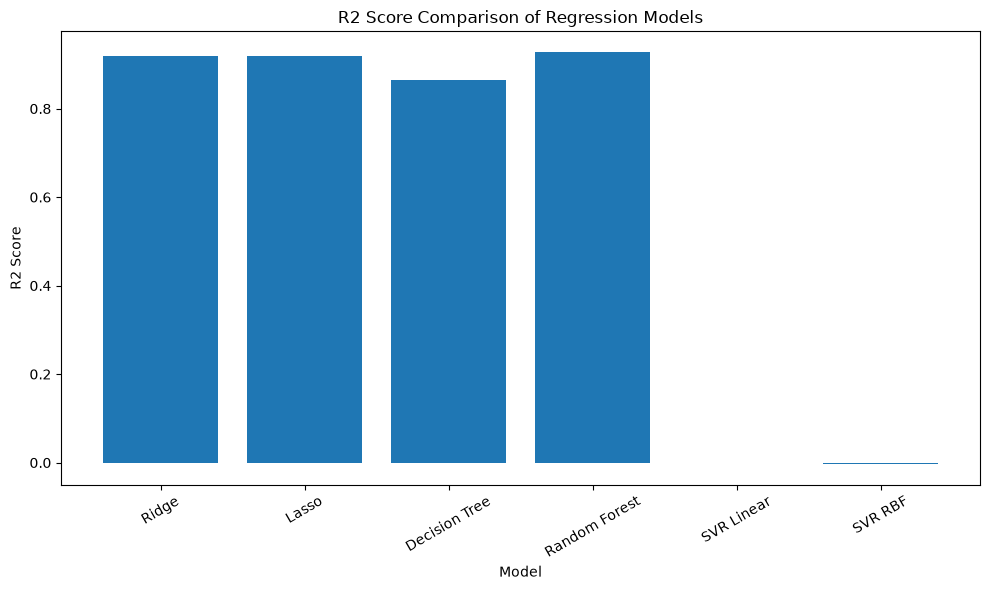

In [82]:
plt.figure(figsize=(10, 6))

plt.bar(evaluation_table["Model"],evaluation_table["R2 Score"])

plt.xlabel("Model")
plt.ylabel("R2 Score")
plt.title("R2 Score Comparison of Regression Models")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Interpretation

Random Forest has the highest R² score, followed by Lasso and Ridge, while both SVR models perform very poorly.
This shows that Random Forest gives the best overall predictive performance.

## Task 24 : Identify Overfitting or Underfitting

In [83]:
train_predictions = [
    best_ridge.predict(X_train_scaled),
    best_lasso.predict(X_train_scaled),
    best_tree.predict(X_train),
    rf_train_pred,
    svr_linear.predict(X_train_scaled),
    svr_rbf.predict(X_train_scaled)
]

test_predictions = predictions

train_r2 = []
test_r2 = []

for i in range(len(models)):

    train_r2.append(
        r2_score(y_train, train_predictions[i])
    )

    test_r2.append(
        r2_score(y_test, test_predictions[i])
    )

diagnostics = pd.DataFrame({
    "Model": models,
    "Training R2": train_r2,
    "Test R2": test_r2
})

print(diagnostics.to_string(
    index=False,
    formatters={
        "Training R2": "{:.4f}".format,
        "Test R2": "{:.4f}".format
    }
))

        Model Training R2 Test R2
        Ridge      0.9174  0.9199
        Lasso      0.9174  0.9199
Decision Tree      0.9621  0.8656
Random Forest      0.9893  0.9282
   SVR Linear     -0.0058 -0.0019
      SVR RBF     -0.0069 -0.0029


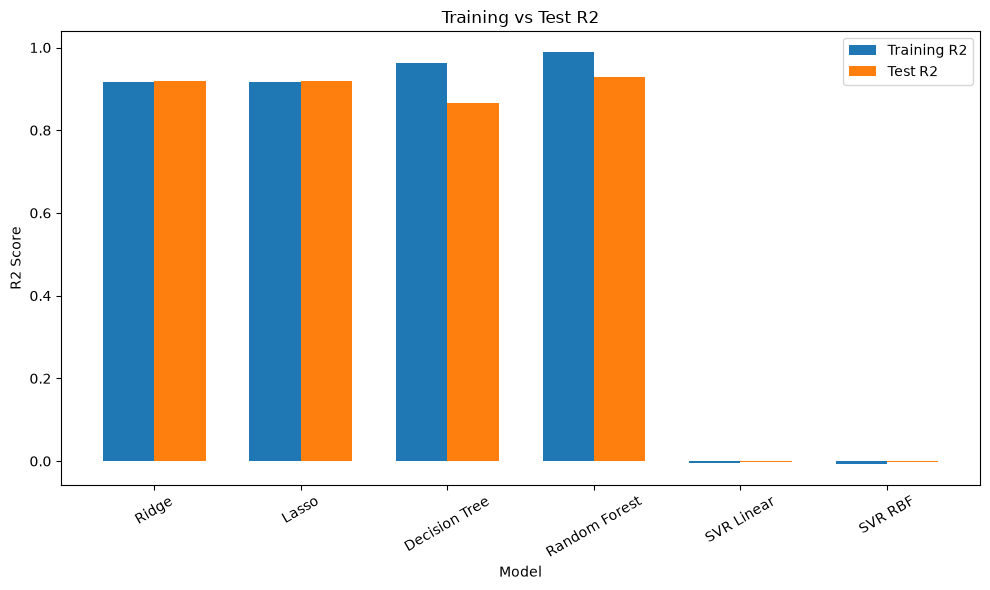

In [53]:
plt.figure(figsize=(10, 6))

x = np.arange(len(models))
width = 0.35

plt.bar(x - width/2, train_r2, width, label="Training R2")
plt.bar(x + width/2, test_r2, width, label="Test R2")

plt.xlabel("Model")
plt.ylabel("R2 Score")
plt.title("Training vs Test R2")

plt.xticks(x, models, rotation=30)
plt.legend()

plt.tight_layout()
plt.show()

### Interpretation

Ridge and Lasso have very similar training and test R², showing stable generalization.
Decision Tree and Random Forest show a larger gap, indicating some overfitting, while SVR shows underfitting.

# Part H: Final Analysis & Reporting

## Task 25: Final Report

### Best-Performing Model

- Random Forest Regression performed the best among all the tested models. It achieved the highest test R² score of 0.9282 and the lowest MSE of 5,785,958,403,336.22.

- It performed better than Ridge, Lasso, Decision Tree, and both SVR models, showing that the ensemble tree-based model was able to capture the relationships in the housing data more effectively.

### Impact of Regularization

- Ridge and Lasso produced very similar results. Lasso achieved a slightly lower validation MSE and test MSE than Ridge.

- The coefficients of both models were also very similar. Lasso reduced the coefficients slightly but did not reduce any feature coefficient to zero. Therefore, regularization provided stable predictions, but there was very little difference between Ridge and Lasso for this dataset.

### Role of Cross-Validation in Model Stability

- The cross-validation results were very similar across K-Fold, Stratified K-Fold, and Time Series Split, with R² values around 0.916 to 0.917.

- Stratified K-Fold gave the highest mean R² of 0.9167, while Time Series Split gave 0.9162. This shows that the model performance was relatively stable across different validation strategies.

- LOOCV was evaluated using MSE because R² is not applicable when each validation fold contains only one observation.

### Linear vs Non-Linear Regression

- The regularized linear models performed strongly, with both Ridge and Lasso achieving a test R² of 0.9199.

- Random Forest performed slightly better with a test R² of 0.9282, showing that the data contains relationships that can be captured better by a non-linear ensemble model.

- The Decision Tree achieved a lower test R² of 0.8917, while both SVR models performed poorly, with R² values close to zero.

### Evidence of Overfitting and Underfitting

- The Decision Tree shows signs of overfitting because its training R² is 0.9621 while its test R² falls to 0.8917.

- Random Forest also has a high training R² of 0.9893, but its test R² remains high at 0.9282. This shows some variance but better generalization than the single Decision Tree.

- Ridge and Lasso have very similar training and test R² values, indicating stable generalization.

- Both SVR models show underfitting because their training and test R² values are close to zero and even slightly negative.

### Business Interpretation

- The results show that house prices can be predicted effectively using multiple property-related features such as area, location score, property age, distance from the city, nearby facilities, and crime rate.

- A real estate analytics company can use the Random Forest model to estimate property prices and support pricing, valuation, and investment decisions. The model's test R² of 0.9282 indicates that it explains a large proportion of the variation in house prices.


### Final Conclusion

Among all the models tested, Random Forest Regression was the best-performing model with a test R² score of 0.9282 and the lowest test MSE.

Ridge and Lasso also performed well and showed stable generalization, while the Decision Tree showed some overfitting. Both SVR models underperformed on this dataset.

Overall, Random Forest provides the best balance between predictive performance and generalization for this house price prediction problem.

Explanation Video: https://drive.google.com/file/d/1mNM2ZxQ9GSMTT22E-Uvepi9f4Wj1I-pu/view?usp=drive_link

# Part I: Model Export for Deployment

### Task 26: Save Trained Model using Joblib

In [76]:
# Export the trained model for production deployment
import joblib

# Save the best-performing model (Random Forest)
joblib.dump(rf_model, 'house_price_model.pkl')

print("Model successfully saved as 'house_price_model.pkl'")

Model successfully saved as 'house_price_model.pkl'
